In [79]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from clickhouse_driver import Client
import pandas as pd
client = Client(host='', port=000, user='',
                password='', database='')

def get_data(query):
    """
    Вытягивает данные из clickhouse в виде Dataframe
    
    query - запрос
    """
    result, columns = client.execute(query, with_column_types=True)
    return pd.DataFrame(result, columns=[tuple[0] for tuple in columns])

### Задача 1. Выгрузка и подготовка данных 

In [81]:
import numpy as np



data = get_data("""
    SELECT 
        la.*
        , up.user_type_cars_name 
    FROM hardda.live_adverts as la
    LEFT JOIN hardda.user_passports up
        USING(passport_id)
    WHERE 1=1
        AND execution_date BETWEEN '2022-10-01' AND '2022-11-01'
        AND region = 'Красноярск'
    --limit 25
""")

data['execution_date'] = pd.to_datetime(data['execution_date'])
data['created_at'] = pd.to_datetime(data['created_at'])

data

,execution_date,advert_id,created_at,price,region,user_id,platform,auto_brand,auto_model,passport_id,year,userType,user_type_cars_name
0,2022-10-01,134816894,2013-06-25 16:10:00,0,Красноярск,124088110,desktop,Unknown,Unknown model,124109130,0,0,cars_simple
1,2022-10-01,139593230,2014-05-14 07:00:22,0,Красноярск,123488190,desktop,Unknown,Unknown model,123508931,0,0,cars_simple
2,2022-10-01,140854575,2014-07-28 04:03:11,0,Красноярск,123927406,desktop,Unknown,Unknown model,123948401,2022,7,cars_dealer
3,2022-10-01,143662578,2015-01-09 16:47:38,12000000,Красноярск,123510982,unknown,Unknown,Unknown model,123531907,2014,0,cars_simple
4,2022-10-01,144648900,2015-02-25 04:32:28,192000,Красноярск,123927406,desktop,Unknown,Unknown model,123948401,2020,7,cars_dealer
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195126,2022-10-16,266962931,2022-10-13 13:44:50,640000,Красноярск,127589816,android,Skoda,Octavia,127287205,2012,0,cars_simple
195127,2022-10-16,266962978,2022-10-13 13:46:25,860000,Красноярск,144677804,ios,BMW,328,140158117,2006,0,cars_simple
195128,2022-10-16,266963097,2022-10-13 13:49:05,700000,Красноярск,135410345,android,Volkswagen,Jetta,132546904,2007,0,cars_simple
195129,2022-10-16,266963112,2022-10-13 13:49:29,320000,Красноярск,149325440,android,ВАЗ (Lada),Priora 2171 (универсал),143920008,2011,0,cars_simple


У нас есть датасет с сырыми данными. На этом шаге мы соберём из него датасет, в котором будут только интересующие нас объявления: актуальные на 1 октября и только такие, где мы знаем, утечёт создатель этого объявления через месяц или нет.

#### Считаем таргет
Подумайте, как бы вы посчитали таргет для каждого passport_id, учитывая описанное на предыдущем степе. Ниже один из вариантов, как это можно сделать.

Для каждого пользователя (passport_id) посчитайте минимальную и максимальную дату активного объявления (execution_date). Проще всего сразу сделать датафрейм, где будет passport_id и две даты, т.к. потом его будет удобно фильтровать, добавлять столбцы и т.д.


Оставьте только строки, где минимальная дата это 1 октября. У остальных пользователей не было объявлений на дату начала эксперимента, и нас они не интересуют.

Посчитайте разницу в днях между 1 ноября 2022 г. и максимальной датой объявления пользователя. Получится количество дней до 1 ноября, в течение которых пользователь был неактивен. Добавьте такой столбец в датафрейм.

Оставьте только строки, где полученное количество неактивных дней перед 1 ноября либо равно 0 (тогда это очевидный "не отток"), либо строго больше 14 (это считаем оттоком). Теперь у нас остались только пользователи, про которых мы чётко можем сказать, отток это или нет, а всех остальных, где "неясно", мы отбросили.

Выставим таргет. Добавьте столбец churn: если количество неактивных дней более 14, его значение равно 1 (отток), иначе 0 (не отток).
Оставьте только столбцы passport_id и churn (остальные были вспомогательными для расчётов).

In [82]:
d1 = data.groupby('passport_id').agg(
    min_date=('execution_date', 'min')
    , max_date=('execution_date', 'max')
).reset_index()

d1 = d1[d1['min_date'] == '2022-10-01']

d1['diff_days'] = (pd.to_datetime('2022-11-01') - d1['max_date']).dt.days

dfeat = d1[(d1['diff_days'] == 0) | (d1['diff_days'] > 14)]
dfeat['churn'] = np.where(dfeat['diff_days'] > 14, 1, 0)

dfeat = dfeat[['passport_id', 'churn']].reset_index(drop=True)
dfeat.head()

,passport_id,churn
0,123467852,0
1,123469393,0
2,123469843,0
3,123475067,0
4,123476026,0


Собираем датасет с объявлениями
Возвращаемся к датафрейму, полученному на предыдущем степе, со всеми объявлениями за месяц.

Возьмите из него только строки, в которых execution_date равна 2022-10-01 (таргет мы уже собрали, а для признаков нам нужны только объявления, актуальные на дату начала эксперимента).

Сджойните результат с полученным до этого датафреймом (содержащим таргет).


### Что дальше?
Теперь у нас есть датафрейм с объявлениями, актуальными на 1 октября, и в каждом есть информация, продолжит ли пользоваться сервисом создатель этого объявления через месяц.

Теперь нужно каким-то образом сгруппировать информацию, чтобы из датасета с объявлениями перейти к датасету с пользователями, в котором будут признаки пользователя и таргет.

Прежде чем идти дальше, подумайте, как это сделали бы вы.

И давайте снова убедимся, что у нас получились одинаковые результаты.

Теперь у нас есть датасет с объявлениями и таргетом. Через запятую и пробел введите количество строк в полученном датафрейме и количество уникальных пользователей в нём. Например, 5432, 4321.

In [83]:
data1 = data[data['execution_date'] == '2022-10-01'].reset_index(drop=True)
datadfeat = pd.merge(data1, dfeat, on='passport_id')
datadfeat.shape[0], datadfeat['passport_id'].nunique()

(4367, 3441)

### Задача 2. Признаки пользователя

Нам нужно сгруппировать и сагрегировать объявления по каждому пользователю, чтобы из датафрейма с объявлениями получить датафрейм с пользователями.

Будем решать задачу итеративно, постепенно добавляя в агрегацию новые поля. Иногда нам нужно будет сделать что-то дополнительно перед группировкой и агрегацией.

1. Начнём с самого очевидного. По каждому пользователю посчитаем текущее количество живых объявлений. Назовите получившийся столбец opening_adverts_amount. Идея признака проста: если у пользователя много активных объявлений, менее вероятно, что он утечёт в ближайший месяц.

2. Посчитаем среднюю цену объявлений пользователя.

Это менее очевидный признак, но раз в объявлениях есть цена, нужно это использовать. Например, может оказаться, что более дорогие машины продаются дольше, и пользователь с меньшей вероятностью уйдёт в ближайший месяц.

Со столбцом price есть небольшая проблема, которую нам нужно решить перед группировкой: есть объявления с ценой равной 0. Вряд ли автомобили отдают бесплатно, более вероятно, что это пропущенные значения.

Перед группировкой замените значение 0 на np.nan в столбце с ценами. И уже после этого добавьте столбец в агрегацию, посчитав среднее. Полученный столбец назовите price.

При агрегации pandas посчитает среднее по непустым ценам. Но где-то останутся пропуски. С этим мы будем разбираться потом, в пайплайне предподготовки данных.

В поле ниже введите два числа через запятую и пробел:

Среднее значение opening_adverts_amount в полученном датафрейме, округлённое до 3 знаков.

Максимальное значение price, округлённое до целого.



In [84]:
datadfeat['price'] = datadfeat['price'].replace(0, np.nan)
data_feat = datadfeat.groupby('passport_id').agg(
    opening_adverts_amount=('advert_id', 'count'),
    price=('price','mean')
).reset_index()

print(round(data_feat['opening_adverts_amount'].mean(),3)
    , round(data_feat['price'].max()))

1.269 24000000


Добавим ещё два признака.

auto_age
Посчитаем средний возраст автомобилей пользователя. Перед агрегацией нужно сначала сделать несколько вещей:

Исправьте тип столбца year на int.
Как и в случае с ценой, встречаются значения года, равные 0. Если про цену ещё могли быть сомнения, то тут это точно пропуск. Замените значение 0 на np.nan.
Добавьте в датасет с объявлениями столбец auto_age, полученный как разность между 2022 ("текущим" годом) и year.
Теперь у нас в каждом объявлении есть возраст автомобиля. Добавьте его в агрегацию, взяв среднее. Полученный столбец назовите тоже auto_age.

advert_age
Также посчитаем средний возраст объявлений пользователя (в днях).

Логика признака может быть разной. С одной стороны, если объявление давно висит, возможно, оно уже собрало достаточно просмотров. Машина скоро продастся, а клиент, если он — физическое лицо, после продажи может навсегда пропасть с платформы. С другой стороны, если у пользователя есть активные объявления, которые давно висят, очень может быть, что они повисят и ещё месяц. В любом  случае, есть вероятность, что такой признак даст модели полезную информацию.

Сначала для датасета с объявлениями посчитайте разность между датой 2022-10-01 и датой created_at. Обратите внимание, что из created_at берём только дату. Из полученной разности возьмите количество дней и добавьте в датафрейм как столбец advert_age.

При агрегации возьмите среднее по этому столбцу. Полученный столбец назовите тоже advert_age.

В поле ниже через запятую и пробел введите два числа:

Медиану auto_age, округлённую до целого.
Максимальный advert_age, тоже округлённый до целого.

In [85]:

datadfeat['year'] = datadfeat['year'].astype(float).fillna(0).astype(int).replace(0, np.nan)
datadfeat['auto_age'] = 2022 - datadfeat['year']
data_age = datadfeat.groupby('passport_id').agg(
    auto_age=('auto_age', 'mean')
).reset_index()

features = pd.merge(data_feat, data_age, how='left', on='passport_id')
# features
datadfeat['diff_date_created'] = (pd.to_datetime('2022-10-01') - datadfeat['created_at'].dt.normalize()).dt.days
data_advert_age = datadfeat.groupby('passport_id').agg(
    advert_age=('diff_date_created','mean')
).reset_index()


features_2 = pd.merge(features, data_advert_age, how='left', on='passport_id')

print(round(features_2['auto_age'].median()),
    round(features_2['advert_age'].max()))

14 3385


platform
Добавим в агрегацию столбец с основной платформой пользователя. Вдруг это тоже влияет на отток.

Если нельзя однозначно определить наиболее популярную платформу, то отдавайте предпочтение android > ios > desktop  > mobile > unknown (т.е. если одно объявление с android и одно с desktop, то основная платформа — android).

Создайте такой признак, назовите его platform.



In [86]:
PRIORITY = {'android': 1, 'ios': 2, 'desktop': 3, 'mobile': 4, 'unknown': 5}

kk = datadfeat.groupby(['passport_id', 'platform']).size().reset_index(name='counts')
kk['priority'] = kk['platform'].map(PRIORITY)
kk = kk.sort_values(by=['counts', 'priority'], ascending=[False, True])

top_platform = kk.drop_duplicates('passport_id', keep='first')
top_platform = top_platform[['passport_id', 'platform']]

features_3 = features_2.merge(top_platform, how='left', on='passport_id')
features_3['platform'].value_counts()

platform
android    2250
ios        1042
desktop     148
unknown       1
Name: count, dtype: int64

is_top_model

Создадим признак "есть ли среди объявлений пользователя машины, из топ-10 моделей". Идея признака в том, что популярные, "ходовые" товары обычно продаются быстрее.

В датафрейме, который мы агрегируем, найдите 10 наиболее часто встречаемых auto_model, не считая Unknown model.

Для каждого объявления посчитайте, входит является ли оно продажей модели из топ-10 (1 если да, 0 если нет).

Подумайте, какая функция агрегации тут подойдёт, если нас интересует, есть ли у пользователя хотя бы одно такое объявление.

Полученный признак назовите is_top_model.

У скольки пользователей значение признака равно 1?

In [87]:
top10_models = datadfeat[datadfeat['auto_model'] != 'Unknown model']['auto_model'].value_counts()[:10].reset_index()['auto_model']

datadfeat['is_top'] = np.where(datadfeat['auto_model'].isin(top10_models), 1, 0)
model = datadfeat.groupby('passport_id').agg(
    is_top_model = ('is_top', 'max')
).reset_index()

features_4 = features_3.merge(model, how='left', on='passport_id')
features_4[features_4['is_top_model'] == 1]

,passport_id,opening_adverts_amount,price,auto_age,advert_age,platform,is_top_model
5,123478402,2,2600000.0,8.0,4.0,ios,1
6,123487887,1,2660000.0,2.0,24.0,desktop,1
9,123499101,2,1368000.0,1.5,20.0,android,1
11,123501036,1,3200000.0,5.0,3.0,ios,1
14,123505010,1,410000.0,10.0,3.0,android,1
...,...,...,...,...,...,...,...
3415,144325620,1,500000.0,21.0,1.0,android,1
3421,144328090,1,560000.0,9.0,1.0,android,1
3426,144330880,1,150000.0,19.0,0.0,android,1
3427,144331222,1,100000.0,12.0,0.0,android,1


user_type_cars_name
Перенесём сюда user_type_cars_name из объявлений. Тут никаких хитростей: т.к. мы проджойнивали этот столблец по passport_id из другой таблицы, для каждого passport_id будет только одно значение user_type_cars_name. Подумайте, какая функция агрегации здесь будет наиболее очевидной.

churn
Хоть это и не признак, но не забудем при группировке добавить таргет. Тут тоже всё просто.

Ещё скрытые пропуски
Как мы видели до этого, в столбце с годом были значения 0. Вроде бы не пропуск, .isna() не поймает. Но по факту пропущенное значение.

В категориальных столбцах такое тоже может быть:

В столбце user_type_cars_name есть значение '' (пустая строка). Давайте заменим его на np.nan, чтобы явно указать, что мы рассматриваем его как пропуск. Из-за некоторых особенностей pandas чуть проще это сделать уже после группировки и агрегации (иначе может появиться значение None и потребуется чуть больше шагов). Если вдруг вы сохраняли какой-то из датафреймов в csv и читали из него, у вас может уже быть nan, тогда ничего делать не нужно.
В столбце platform есть значение unknown. В другой ситуации мы могли бы оставить "unknown" отдельной категорией. Но поскольку строка с таким значением только одна, удобнее будет рассматривать его как пропуск. Замените это значение на np.nan в получившемся после группировке датафрейме.
Готово. У нас есть датафрейм с пользователями. В нём должно получиться 9 столбцов (включая passport_id и таргет) и столько строк, сколько было уникальных пользователей в датасете с объявлениями.

При группировке данные должны были автоматически отсортироваться. Но на всякий случай проверьте, что датафрейм отсортирован по возрастанию passport_id. Это для воспроизводимости.

Посмотрите, сколько получилось пользователей с разным типом user_type_cars_name.

Какой наименее частый тип user_type_cars_name? Сколько там пользователей?

Введите название (без кавычек) и количество пользователей через запятую и пробел. Например, cars_seller, 1200.

In [88]:
features_5 = features_4.merge(datadfeat.groupby('passport_id')[['user_type_cars_name','churn']]
                              .first().reset_index(), how='left', on='passport_id')

features_5['user_type_cars_name'] = features_5['user_type_cars_name'].replace('', np.nan)
features_5['platform'] = features_5['platform'].replace('unknown', np.nan)
features_5 = features_5.sort_values(by='passport_id', ascending=True)
features_5['passport_id'].is_monotonic_increasing

print(features_5['user_type_cars_name'].value_counts())



user_type_cars_name
cars_simple    2970
cars_seller     321
cars_dealer      37
Name: count, dtype: int64


Разбейте датафрейм на X и y. В X пойдут все столбцы кроме passport_id и таргета.

Train и test
Разбейте данные на train и test. Используйте test_size=0.2, random_state=42. Также, поскольку это задача классификации, добавьте параметр stratify=y, чтобы в train и test получились такие же пропорции классов, какие были до разбиения.

Посмотрите, какие доли классов были в исходном датафрейме. Убедитесь, что в train и test получились примерно такие же.

Как обсуждали на предыдущем шаге, это значение также задаёт бейслайн значения оптимизируемой метрики.

Какова доля класса 1 в каждом из датасетов? Округлите значение до 3 знаков после точки, например, 0.456. Введите одно число, т.к. с точностью до 3 знаков значение будет одинаковым для каждой из выборок.

In [89]:
from sklearn.model_selection import train_test_split

X = features_5.drop(columns=['passport_id', 'churn'])
y = features_5['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [90]:
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))
print(f'''Для ответа:

{round(features_5['churn'].value_counts(normalize=True).iloc[0],3)}''')

(2752, 7) (689, 7)
churn
1    0.50436
0    0.49564
Name: proportion, dtype: float64
churn
1    0.503628
0    0.496372
Name: proportion, dtype: float64
Для ответа:

0.504


In [91]:
X_train.columns.to_list()

['opening_adverts_amount',
 'price',
 'auto_age',
 'advert_age',
 'platform',
 'is_top_model',
 'user_type_cars_name']

In [92]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.compose import make_column_selector as selector
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

cat_platform = ['platform']
cat_user_type = ['user_type_cars_name']
cat_cols = cat_platform + cat_user_type

numeric_cols = [c for c in X_train.columns if c not in cat_cols]

imputer = ColumnTransformer(transformers=[
    ('imputer_platform', SimpleImputer(strategy='most_frequent'), cat_platform),
    ('impute_type_cars', SimpleImputer(strategy='constant', fill_value='unknown'), cat_user_type), 
    ('impute_num', SimpleImputer(strategy='mean'), numeric_cols),
    ], 
    remainder='passthrough',
    verbose_feature_names_out=False
)

encoder = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
    )


pipe = Pipeline(steps=[
    ('imputer', imputer),
    ('encoder', encoder),
    ('scaler', StandardScaler())
]).set_output(transform='pandas')


X_train_transformed = pipe.fit_transform(X_train)
print(X_train_transformed.shape)
print(X_train_transformed.dtypes)
print(X_train_transformed.isna().sum().sum())
# print(X_train_transformed.head())

X_train_transformed.to_csv(fr'C:\Users\alexx\Desktop\HARD_DA\X_train_transformed.csv', index=False)
X_train_transformed.head()


(2752, 10)
platform_desktop                   float64
platform_ios                       float64
user_type_cars_name_cars_seller    float64
user_type_cars_name_cars_simple    float64
user_type_cars_name_unknown        float64
opening_adverts_amount             float64
price                              float64
auto_age                           float64
advert_age                         float64
is_top_model                       float64
dtype: object
0


,platform_desktop,platform_ios,user_type_cars_name_cars_seller,user_type_cars_name_cars_simple,user_type_cars_name_unknown,opening_adverts_amount,price,auto_age,advert_age,is_top_model
2682,-0.219957,1.532296,-0.323693,0.404520,-0.193174,-0.202769,-0.596921,0.068329,1.491521,-0.616555
6,4.546349,-0.652615,3.089346,-2.472066,-0.193174,-0.202769,1.160889,-1.508082,-0.203416,1.621915
2649,-0.219957,1.532296,-0.323693,0.404520,-0.193174,-0.202769,-0.613715,0.189591,-0.319580,-0.616555
2590,-0.219957,-0.652615,3.089346,-2.472066,-0.193174,-0.202769,-0.511550,-0.052933,-0.118934,-0.616555
3032,-0.219957,-0.652615,-0.323693,0.404520,-0.193174,-0.202769,-0.168665,0.432116,-0.330141,-0.616555


In [93]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import CalibratedClassifierCV

In [94]:
class ThresholdClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, base_model, threshold=0.5):
        self.base_model = base_model
        self.threshold = threshold 

    def fit(self, X, y):
        if not hasattr(self.base_model, 'predict_proba'):
            self.base_model = CalibratedClassifierCV(self.base_model, cv=3)

        self.base_model.fit(X, y)
        self.classes_ = self.base_model.classes_

        return self 

    def predict_proba(self, X):
        return self.base_model.predict_proba(X)

    def predict(self, X):
        proba = self.predict_proba(X)[:, 1]
        return (proba >= self.threshold).astype(int)


In [95]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe_log_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])

clf = ThresholdClassifier(pipe_log_reg, threshold=0.5)
clf.fit(X_train_transformed, y_train)


print(clf.classes_)               # [0, 1]
print(clf.predict(X_train_transformed).mean())
print(clf.predict_proba(X_train_transformed)[:5])

[0 1]
0.6726017441860465
[[0.58039587 0.41960413]
 [0.78177288 0.21822712]
 [0.4200581  0.5799419 ]
 [0.71669929 0.28330071]
 [0.43528524 0.56471476]]


In [96]:
import pandas as pd

def make_refit_with_recall_threshold(recall_threshold):
    def refit_with_threshold(cv_results):
        cv_results = pd.DataFrame(cv_results)
        res_cv = cv_results[cv_results['mean_test_recall'] > recall_threshold]

        if res_cv.empty:
            raise ValueError(
                f"Ни одна модель не показала mean_test_recall > {recall_threshold}"
            )
        return res_cv['mean_test_precision'].idxmax()
    
    return refit_with_threshold

refit = make_refit_with_recall_threshold(recall_threshold=0.8)

In [97]:
from sklearn.metrics import precision_score, make_scorer
from sklearn.model_selection import StratifiedKFold, GridSearchCV


scoring = {
    'precision' : make_scorer(precision_score, zero_division = 0)
    , 'recall': 'recall'
}

splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

pipe_fit = Pipeline(steps=[
    ('all_preprocces', pipe),
    ('simple_model', ThresholdClassifier(base_model=LogisticRegression(random_state=42, solver='liblinear')))
])

# print(pipe_fit.get_params().keys())

param_grid = {'simple_model__base_model__C': [0.0001, 0.01, 1, 100, 10000],
            'simple_model__threshold' : [0.4, 0.5, 0.6]}

log_reg = GridSearchCV(
    estimator=pipe_fit,
    param_grid=param_grid,
    cv = splitter,
    scoring=scoring,
    refit=refit
)

log_reg.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iblinear')))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'simple_model__base_model__C': [0.0001, 0.01, ...], 'simple_model__threshold': [0.4, 0.5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'precision': make_scorer(p...ro_division=0), 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",<function mak...00240685FD580>
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the ver

In [98]:
cols = [
    'param_simple_model__base_model__C',
    'param_simple_model__threshold',
    'mean_test_precision',
    'mean_test_recall',
]

results = pd.DataFrame(log_reg.cv_results_)[cols]
results

,param_simple_model__base_model__C,param_simple_model__threshold,mean_test_precision,mean_test_recall
0,0.0001,0.4,0.504360,1.000000
1,0.0001,0.5,0.572143,0.809773
2,0.0001,0.6,0.000000,0.000000
3,0.0100,0.4,0.552220,0.923604
4,0.0100,0.5,0.585529,0.800405
5,0.0100,0.6,0.695432,0.274490
6,1.0000,0.4,0.569843,0.891903
7,1.0000,0.5,0.593722,0.795362
8,1.0000,0.6,0.685969,0.337940
9,100.0000,0.4,0.570559,0.892623


Исходя из результатов предыдущего шага, попробуем перебрать такие значения гиперпараметров:

C: 0.1, 1, 10, 100, 1000.
threshold: 0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.50, 0.51. Скорее всего, нужно что-то чуть меньше 0.5, но возьмём с запасом в обе стороны, больше в сторону 0.4.
penalty: 'l1', 'l2'.

In [99]:
param_grid_2 = {'simple_model__threshold' : [0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.50, 0.51],
            'simple_model__base_model__penalty':['l1', 'l2'],
            'simple_model__base_model__C' : [0.1, 1, 10, 100, 1000]}

# pipe_fit.get_params().keys()

log_reg = GridSearchCV(
    estimator=pipe_fit,
    param_grid=param_grid_2,
    cv = splitter,
    scoring=scoring,
    refit=refit
)

log_reg.fit(X_train, y_train)

def set_best_score(grid_search):
    grid_search.best_score_ = grid_search.cv_results_['mean_test_precision'][grid_search.best_index_]

set_best_score(log_reg)

In [100]:
def cv_results_dataframe(grid, recall_threshold=0.8, max_rows=10):
    cols = (
        [k for k in grid.cv_results_.keys() if k.startswith('param_')] +
        ['mean_test_precision', 'mean_test_recall']
    )
    res = pd.DataFrame(grid.cv_results_)[cols]
    res = res[res['mean_test_recall'] > recall_threshold]
    return res.sort_values('mean_test_precision', ascending=False).head(max_rows)

cv_results_dataframe(log_reg).iloc[0]

print(round(cv_results_dataframe(log_reg).iloc[0].loc['mean_test_precision'],3))
print(round(cv_results_dataframe(log_reg).iloc[0].loc['param_simple_model__base_model__C'],3))
print(cv_results_dataframe(log_reg).iloc[0].loc['param_simple_model__base_model__penalty'])
print(round(cv_results_dataframe(log_reg).iloc[0].loc['param_simple_model__threshold'],3))


0.593
10.0
l2
0.49


In [101]:
log_reg.get_params().keys()

dict_keys(['cv', 'error_score', 'estimator__memory', 'estimator__steps', 'estimator__transform_input', 'estimator__verbose', 'estimator__all_preprocces', 'estimator__simple_model', 'estimator__all_preprocces__memory', 'estimator__all_preprocces__steps', 'estimator__all_preprocces__transform_input', 'estimator__all_preprocces__verbose', 'estimator__all_preprocces__imputer', 'estimator__all_preprocces__encoder', 'estimator__all_preprocces__scaler', 'estimator__all_preprocces__imputer__force_int_remainder_cols', 'estimator__all_preprocces__imputer__n_jobs', 'estimator__all_preprocces__imputer__remainder', 'estimator__all_preprocces__imputer__sparse_threshold', 'estimator__all_preprocces__imputer__transformer_weights', 'estimator__all_preprocces__imputer__transformers', 'estimator__all_preprocces__imputer__verbose', 'estimator__all_preprocces__imputer__verbose_feature_names_out', 'estimator__all_preprocces__imputer__imputer_platform', 'estimator__all_preprocces__imputer__impute_type_cars',

In [102]:
pipe_fit.get_params().keys()

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'all_preprocces', 'simple_model', 'all_preprocces__memory', 'all_preprocces__steps', 'all_preprocces__transform_input', 'all_preprocces__verbose', 'all_preprocces__imputer', 'all_preprocces__encoder', 'all_preprocces__scaler', 'all_preprocces__imputer__force_int_remainder_cols', 'all_preprocces__imputer__n_jobs', 'all_preprocces__imputer__remainder', 'all_preprocces__imputer__sparse_threshold', 'all_preprocces__imputer__transformer_weights', 'all_preprocces__imputer__transformers', 'all_preprocces__imputer__verbose', 'all_preprocces__imputer__verbose_feature_names_out', 'all_preprocces__imputer__imputer_platform', 'all_preprocces__imputer__impute_type_cars', 'all_preprocces__imputer__impute_num', 'all_preprocces__imputer__imputer_platform__add_indicator', 'all_preprocces__imputer__imputer_platform__copy', 'all_preprocces__imputer__imputer_platform__fill_value', 'all_preprocces__imputer__imputer_platform__keep_empty_features', 

In [103]:
logreg_grid_elasticnet = {
    'simple_model__base_model__C' :  [1],
    'simple_model__base_model__penalty': ['l1', 'l2'],
    'simple_model__threshold': [0.35],
}

search_elastic = GridSearchCV(pipe_fit,
                            param_grid=logreg_grid_elasticnet,
                            scoring=scoring, refit=refit,
                            cv=splitter)

search_elastic.fit(X_train, y_train)
cv_results_dataframe(search_elastic)

,param_simple_model__base_model__C,param_simple_model__base_model__penalty,param_simple_model__threshold,mean_test_precision,mean_test_recall
0,1,l1,0.35,0.564873,0.927208
1,1,l2,0.35,0.564868,0.927208


In [104]:
pipe_fit.get_params().keys()

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'all_preprocces', 'simple_model', 'all_preprocces__memory', 'all_preprocces__steps', 'all_preprocces__transform_input', 'all_preprocces__verbose', 'all_preprocces__imputer', 'all_preprocces__encoder', 'all_preprocces__scaler', 'all_preprocces__imputer__force_int_remainder_cols', 'all_preprocces__imputer__n_jobs', 'all_preprocces__imputer__remainder', 'all_preprocces__imputer__sparse_threshold', 'all_preprocces__imputer__transformer_weights', 'all_preprocces__imputer__transformers', 'all_preprocces__imputer__verbose', 'all_preprocces__imputer__verbose_feature_names_out', 'all_preprocces__imputer__imputer_platform', 'all_preprocces__imputer__impute_type_cars', 'all_preprocces__imputer__impute_num', 'all_preprocces__imputer__imputer_platform__add_indicator', 'all_preprocces__imputer__imputer_platform__copy', 'all_preprocces__imputer__imputer_platform__fill_value', 'all_preprocces__imputer__imputer_platform__keep_empty_features', 

In [105]:
logreg_grid_elasticnet = {
    'simple_model__base_model__C' :  [1],
    'simple_model__base_model__penalty': ['l1', 'l2'],
    'simple_model__threshold': [0.35]
}

search_elastic_net = GridSearchCV(pipe_fit,
                                param_grid=logreg_grid_elasticnet,
                                scoring=scoring, refit=refit,
                                cv=splitter)
                                
search_elastic_net.fit(X_train, y_train)
cv_results_dataframe(search_elastic_net)

,param_simple_model__base_model__C,param_simple_model__base_model__penalty,param_simple_model__threshold,mean_test_precision,mean_test_recall
0,1,l1,0.35,0.564873,0.927208
1,1,l2,0.35,0.564868,0.927208


In [106]:
from sklearn.svm import LinearSVC

In [107]:
# svc_pipe.get_params().keys()

In [108]:
svc_pipe = Pipeline(steps=[
    ('all_preproccesss', pipe),
    ('model', LinearSVC(random_state=42, dual='auto'))
])

svc_pipe.get_params().keys()

svc_grid = {'base_model__model__C' : [0.1, 1, 10, 100, 1000],
            'threshold': [0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.50, 0.51]}

pipe_svc = ThresholdClassifier(base_model=svc_pipe)
search_svc = GridSearchCV(estimator=pipe_svc,
                        param_grid=svc_grid, scoring=scoring,
                        refit=refit, cv=splitter)

search_svc.fit(X_train, y_train)
cv_results_dataframe(search_svc)


,param_base_model__model__C,param_threshold,mean_test_precision,mean_test_recall
28,10.0,0.50,0.592091,0.801838
38,100.0,0.50,0.592091,0.801838
48,1000.0,0.50,0.592091,0.801838
18,1.0,0.50,0.591981,0.800398
8,0.1,0.50,0.590982,0.800397
47,1000.0,0.49,0.589405,0.815530
27,10.0,0.49,0.589405,0.815530
37,100.0,0.49,0.589405,0.815530
7,0.1,0.49,0.589347,0.813368
17,1.0,0.49,0.588972,0.814088


### Какая из моделей справилась лучше?

In [109]:
print(cv_results_dataframe(search_svc).iloc[0])
print()
print(cv_results_dataframe(log_reg).iloc[0])

param_base_model__model__C    10.000000
param_threshold                0.500000
mean_test_precision            0.592091
mean_test_recall               0.801838
Name: 28, dtype: float64

param_simple_model__base_model__C              10.0
param_simple_model__base_model__penalty          l2
param_simple_model__threshold                  0.49
mean_test_precision                        0.592511
mean_test_recall                           0.811211
Name: 57, dtype: object


Результаты практически одинаковые.

Попробуем добавить информацию о транзакционной активности клиентов.

Кажется, что различного рода транзакции (продажи / покупки и пр.) могут быть хорошим сигналом для оттока. Если клиент часто и объемно транзачит, то, скорее всего, с нашим сервисом его связывает больше вещей, чем продавцов, которые не пользуются премиальными услугами, не возобновляют подписки и так далее.

Посмотрите на клиентские транзакции в таблице user_transactions за период между 2022-09-01 и 2022-10-01 включительно (вспомним таймлайн: мы хотим из 1 октября предсказать, что случится 1 ноября; так что берём транзакции за предыдущий месяц, сентябрь).

Объединим типы транзакций в более общие классы:

1) Транзакции класса revenue, если type in ('basic sale', 'fast sale', 'quick sale')

2) Транзакции класса renewal, если type in ('renewal', 'archived renewal', 'automatic renewal')

3) Транзакции класса premium, если type in ('premium', 'premium weekly')

Для каждого passport_id просуммируйте amount по каждому из 3 классов транзакций. Перед суммами добавьте минус, чтобы результат получился с правильным знаком. Полученные столбцы назовите по классам транзакций: revenue, renewal, premium.

Т.к. мы работаем с Clickhouse, можно использовать удобные функции вроде sumIf (но конечно можно использовать и классический SQL).

Приджойните результаты к нашему датафрейму (который был до разбиения на X/y и train/test). Подумайте, какой тип джойна тут нужен и почему.

Заполните пропуски нулями (только в этих 3 столбцах). Мы это делаем потому, что по смыслу это не пропуски (которые "на самом деле" ненулевые, просто у нас нет о них информации), а именно что отсутствие транзакций, нулевые суммы.

Если посмотреть на данные в 3 новых столбцах, видно, что очень просится логарифм, чтобы сделать их более нормальными (тем более учитывая, что мы используем линейные модели). Небольшая проблема в том, что в данных есть нули, а логарифм нуля не определён. Один из вариантов — сначала добавить единичку, а потом взять логарифм. Тогда нули останутся на месте. Прибавьте 1 к значениям трёх новых столбцов и потом прологарифмируйте.

Даже после преобразования данные всё ещё сильно скошенные, но, возможно, логарифмирование всё же поможет моделям.

Посчитайте средние значения для каждого из 3 новых столбцов, округлив до 2 знаков после точки.

Введите значения через запятую и пробел в таком порядке: revenue, renewal, premium.

In [111]:
add_data = get_data('''
    SELECT 
        *, CASE
        WHEN type in ('basic sale', 'fast sale', 'quick sale') THEN 'revenue'
        WHEN type in ('renewal', 'archived renewal', 'automatic renewal') THEN 'renewal'
        WHEN type in ('premium', 'premium weekly') THEN 'premium'
        END AS some_type
    FROM hardda.user_transactions
    WHERE 1=1
        and payment_date BETWEEN '2022-09-01' AND '2022-10-01'
    ''')

In [119]:
agg_data = add_data.groupby(['passport_id', 'some_type']).agg(
    sum_amount=('amount', 'sum')
).reset_index()

agg_data['sum_amount'] = -agg_data['sum_amount']
data_pivot = agg_data.pivot(index='passport_id', columns='some_type', values='sum_amount').reset_index()

add_feat = features_5.merge(data_pivot, how='left', on='passport_id')

add_feat[['premium', 'renewal', 'revenue']] = np.log1p(add_feat[['premium', 'renewal', 'revenue']].fillna(0))

res_type = round(add_feat[['premium', 'renewal', 'revenue']].mean(),2)

print(f"{res_type.loc['revenue']}, {res_type.loc['renewal']}, {res_type.loc['premium']}")


1.68, 2.44, 0.31


Снова выделите из данных X, теперь с дополнительными признаками.

Разбейте его на train и test составляющие
Запустите grid search для логистической регрессии, так же, как до этого, и с той же сеткой гиперпараметров.

Получилось или улучшить качество?

Посмотрите табличку результатами по нескольким лучшим комбинациям гиперпараметров.

Через запятую и пробел введите 4 значения:

Полученное значение метрики precision (округлите до 3 знаков).
Подобранное значение гиперпараметра C.
Значение penalty (без кавычек).
threshold.
Например, 0.543, 1000, l1, 0.48.

In [138]:
X = add_feat.drop(columns=['passport_id', 'churn'])
y = add_feat['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)


pipe_fit_add_deat = Pipeline([
    ('all_preprocces', pipe),
    ('simple_model', ThresholdClassifier(
        base_model=LogisticRegression(random_state=42, solver='liblinear')
        ))
])


param_g = {'simple_model__threshold': [0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.50, 0.51],
           'simple_model__base_model__penalty': ['l1', 'l2'],
           'simple_model__base_model__C':[0.1, 1, 10, 100, 1000]
           }

cv_new_feat = GridSearchCV(estimator=pipe_fit_add_deat,
                        param_grid=param_g, 
                        scoring=scoring,
                        refit=refit, cv=splitter
                        )

cv_new_feat.fit(X_train, y_train)
set_best_score(cv_new_feat)

cv_results_dataframe(cv_new_feat)


,param_simple_model__base_model__C,param_simple_model__base_model__penalty,param_simple_model__threshold,mean_test_precision,mean_test_recall
34,1.0,l2,0.46,0.600408,0.803311
24,1.0,l1,0.46,0.600403,0.803309
74,100.0,l2,0.46,0.599829,0.802588
94,1000.0,l2,0.46,0.599829,0.802588
84,1000.0,l1,0.46,0.599829,0.802588
54,10.0,l2,0.46,0.599826,0.802588
64,100.0,l1,0.46,0.599615,0.801868
44,10.0,l1,0.46,0.599615,0.801868
33,1.0,l2,0.45,0.595857,0.820597
53,10.0,l2,0.45,0.595743,0.821317


In [142]:
svc_pipe_new_feat = Pipeline(steps=[
    ('all_preprocces', pipe),
    ('model', LinearSVC(random_state=42, dual='auto'))
])


pipe_svc_add = ThresholdClassifier(base_model=svc_pipe_new_feat)

param_grid_svc = {'threshold': [0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.50, 0.51],
                'base_model__model__C': [0.1, 1, 10, 100, 1000]}

search_svc_new_feat = GridSearchCV(estimator=pipe_svc_add, 
                                param_grid=param_grid_svc, scoring=scoring,
                                refit=refit, cv=splitter)

search_svc_new_feat.fit(X_train, y_train)
set_best_score(search_svc_new_feat)

cv_results_dataframe(search_svc_new_feat).iloc[0]

param_base_model__model__C    0.100000
param_threshold               0.460000
mean_test_precision           0.601524
mean_test_recall              0.801866
Name: 4, dtype: float64

In [140]:
pipe_svc_add.get_params().keys()

dict_keys(['base_model__memory', 'base_model__steps', 'base_model__transform_input', 'base_model__verbose', 'base_model__all_preprocces', 'base_model__model', 'base_model__all_preprocces__memory', 'base_model__all_preprocces__steps', 'base_model__all_preprocces__transform_input', 'base_model__all_preprocces__verbose', 'base_model__all_preprocces__imputer', 'base_model__all_preprocces__encoder', 'base_model__all_preprocces__scaler', 'base_model__all_preprocces__imputer__force_int_remainder_cols', 'base_model__all_preprocces__imputer__n_jobs', 'base_model__all_preprocces__imputer__remainder', 'base_model__all_preprocces__imputer__sparse_threshold', 'base_model__all_preprocces__imputer__transformer_weights', 'base_model__all_preprocces__imputer__transformers', 'base_model__all_preprocces__imputer__verbose', 'base_model__all_preprocces__imputer__verbose_feature_names_out', 'base_model__all_preprocces__imputer__imputer_platform', 'base_model__all_preprocces__imputer__impute_type_cars', 'bas

Итоговая модель
Новые данные позволили немного улучшить результат, хоть и не очень сильно.

Метрики обеих моделей улучшились примерно одинаково. Формально, чуть выше метрика у SVM, но разница несущественная и, скорее всего, вызвана случайными факторами.

При этом логистическая регрессия — концептуально более простая модель, чем SVM. А если результаты одинаковы, зачем всё усложнять.

Итак, в качестве итоговой модели возьмём логистическую регрессию, обученную на дополненных данных.

Можете вытащить модель из .best_estimator_ соответствующего grid search.

Предсказания
С помощью итоговой модели получите предсказания на тестовой выборке.

Получите отдельно как сами предсказания (0 или 1), так и предсказанные вероятности класса 1.

Проверим, что threshold работает как ожидается. Возьмите предсказанные вероятности. Вручную превратите их в предсказания, используя значение threshold, которое использует итоговая модель. Убедитесь, что результаты полностью совпали с тем, что модель выдаёт в качестве предсказанных классов. И убедитесь, что если использовать другое значение threshold, то результат уже не сойдётся.

Метрики на тесте
Посчитайте precision и recall. Что можно сказать об этих результатах?

В поле ниже введите через запятую и пробел полученные precision и recall (округлите до 3 знаков).

In [145]:
print(final_model.named_steps['simple_model'].threshold)

y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

print(y_pred[:10])
print(y_proba[:10])

0.46
[0 1 0 1 1 1 0 0 1 1]
[0.13332805 0.6278887  0.38392847 0.47211016 0.72095971 0.58759571
 0.23146158 0.32840607 0.5896248  0.69979797]


In [146]:
threshold_used = final_model.named_steps['simple_model'].threshold
print(f"Threshold: {threshold_used}")

y_pred_manual = (y_proba >= threshold_used).astype(int)


print(f"Совпадение: {(y_pred == y_pred_manual).all()}")

y_pred_other = (y_proba >= threshold_used + 0.1).astype(int)
print(f"С другим порогом совпадает: {(y_pred == y_pred_other).all()}")

Threshold: 0.46
Совпадение: True
С другим порогом совпадает: False


In [147]:
from sklearn.metrics import precision_score, recall_score

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred)

print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")

Precision: 0.605
Recall: 0.807


F1
На прошлом степе мы посчитали precision и recall. На основе этих значений прикиньте, каким примерно будет значение метрики F1 (или как минимум в каком интервале оно может находиться).
Чтобы лучше запомнить эту метрику, посчитайте её по формуле, не используя готовые функции.
Посчитайте F1 с помощью готовой функции из sklearn.metrics, сверьте ответ с предыдущим пунктом.
PR-кривая
Постройте PR-кривую и посмотрите на неё.

На графике мы можем видеть, что при recall=1 кривая спускается к нашему бейслайну по precision. А уменьшение recall'а (движение влево по графику) позволяет увеличивать precision. В том числе видно полученное нами значение метрики при пороге 0.8. Ослабляя требование по recall, мы легко можем поднять precision до 0.7. И т.д.

PR-AUC
При построении PR-кривой у нас получились списки precision'ов и recall'ов. Используйте их чтобы посчитать PR-AUC.
Посчитайте PR-AUC другим способом: с помощью функции average_precision_score из sklearn.metrics. Т.к. эта функция использует немного другой способ расчёта, результат будет чуть отличаться (но не сильно).
ROC-кривая и ROC-AUC
Постройте ROC-кривую.

Посчитайте ROC-AUC через данные, полученные при построении ROC-кривой, а потом через готовую функцию. Убедитесь, что результаты полностью совпали.

Через запятую и пробел введите три значения: F1, PR-AUC (вариант через precision_recall_curve + auc) и ROC-AUC. Все значения округлите до 3 знаков. Например, 0.678, 0.678, 0.678.

In [149]:
f1_manual = 2 * (precision * recall) / (precision + recall)
print(f"F1 (вручную): {f1_manual:.4f}")

from sklearn.metrics import f1_score
f1_sklearn = f1_score(y_test, y_pred)
print(f"F1 (sklearn): {f1_sklearn:.4f}")

F1 (вручную): 0.6914
F1 (sklearn): 0.6914


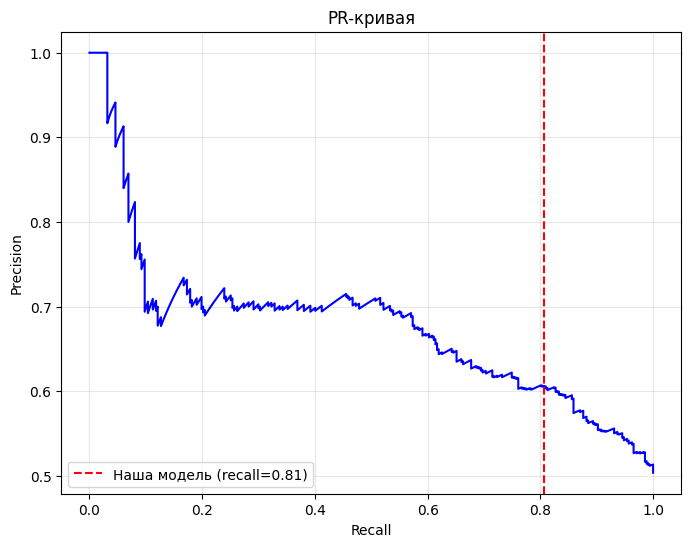

In [151]:
from sklearn.metrics import precision_recall_curve

precision_pts, recall_pts, thresholds = precision_recall_curve(y_test, y_proba)


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(recall_pts, precision_pts, color='blue')
plt.axvline(x=recall, color='red', linestyle='--', label=f'Наша модель (recall={recall:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривая')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [155]:
from sklearn.metrics import auc
from sklearn.metrics import roc_curve, roc_auc_score

pr_auc_manual = auc(recall_pts, precision_pts)
print(f"PR-AUC (ручной): {pr_auc_manual:.4f}")


from sklearn.metrics import average_precision_score

pr_auc_sklearn = average_precision_score(y_test, y_proba)
print(f"PR-AUC (sklearn): {pr_auc_sklearn:.4f}")


fpr, tpr, thresholds_roc = roc_curve(y_test, y_proba)

PR-AUC (ручной): 0.6778
PR-AUC (sklearn): 0.6787


ROC-AUC (ручной): 0.6939
ROC-AUC (sklearn): 0.6939


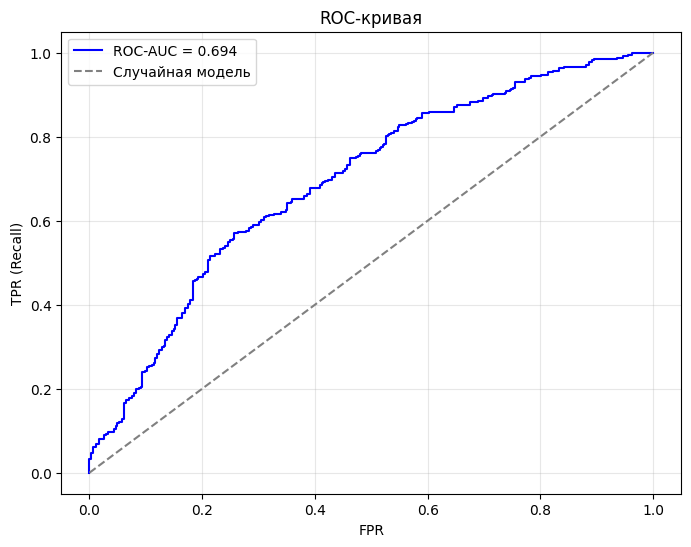

In [158]:
roc_auc_manual = auc(fpr, tpr)
print(f"ROC-AUC (ручной): {roc_auc_manual:.4f}")
roc_auc_sklearn = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC (sklearn): {roc_auc_sklearn:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC-AUC = {roc_auc_manual:.3f}')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Случайная модель')
plt.xlabel('FPR')
plt.ylabel('TPR (Recall)')
plt.title('ROC-кривая')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

0.6069868995633187
make_scorer(precision_at_recall, response_method='predict_proba')


ValueError: Pipeline should either be a classifier to be used with response_method=predict_proba or the response_method should be 'predict'. Got a regressor with response_method=predict_proba instead.